2. SITUAS - Web Scraping

In [5]:
import requests
from bs4 import BeautifulSoup

url_situas = "https://situas.istat.it/web/#/territorio/body?id=74&dateFrom=2020-12-31"

response = requests.get(url_situas, timeout=30)

print("Status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

print(soup.title)
print("Numero link:", len(soup.find_all("a")))

Status code: 200
None
Numero link: 0


We tried to use Beautiful Soup to scrape the data, but it was not successful.

The data is loaded dynamically using JavaScript, so we need to use the API instead.

We opened the developer tools in the browser and went to network tab to find the API endpoint that returns the data in JSON format (that's where we get the payload).

In [ ]:
import requests

url = "https://situas.istat.it/ShibO2Module/api/Report/Spool/2023-12-31/74"

payload = {
    "orderFields": [],
    "orderDirects": [],
    "pFilterFields": [],
    "pFilterValues": []
}

params = {
    "PageNum": 1,
    "PageSize": 10
}

response = requests.post(
    url,
    params=params,
    json=payload,
    timeout=30
)

print("Status code:", response.status_code)
print(response.text[:3000])

Status code: 200
{"label":["Codice Ripartizione geografica","Codice Regione","Codice Provincia (Storico)","Codice Provincia/Uts","Codice Comune (alfanumerico)","Codice Comune (numerico)","Comune","Comune (dizione straniera)","Sigla automobilistica","Capoluogo di Provincia/Uts","Capoluogo di Regione","Popolazione legale","Anno Censimento","Superficie (Kmq)","Anno (Superficie)","Popolazione residente","Anno (Popolazione residente)"],"totalRows":7903,"body":[{"COD_RIP":1,"COD_REG":"01","COD_PROV_STORICO":"001","COD_UTS":"201","PRO_COM_T":"001001","PRO_COM":1001,"COMUNE":"Agliè","SIGLA_AUTOMOBILISTICA":"TO","CC_UTS":0,"CC_REG":0,"POP_LEG":2644,"ANNO_CENSIMENTO":"2011","AREA_KMQ":13.1462,"ANNO_AREA":"2020","POP_RES":2545,"ANNO_POP_RES":"2020"},{"COD_RIP":1,"COD_REG":"01","COD_PROV_STORICO":"001","COD_UTS":"201","PRO_COM_T":"001002","PRO_COM":1002,"COMUNE":"Airasca","SIGLA_AUTOMOBILISTICA":"TO","CC_UTS":0,"CC_REG":0,"POP_LEG":3819,"ANNO_CENSIMENTO":"2011","AREA_KMQ":15.7393,"ANNO_AREA":"2020

We used .post instead of .get because the API endpoint requires a POST request with a JSON payload to return the data.

The payload contains information about the order and filter fields, which are necessary for the API to process the request and return the correct data.

In [9]:
data = response.json()

print(type(data))
print(data.keys())

<class 'dict'>
dict_keys(['label', 'totalRows', 'body', 'colNames', 'formatMasks', 'types'])


In [1]:
import requests
import pandas as pd

url = "https://situas.istat.it/ShibO2Module/api/Report/Spool/2023-12-31/74"

payload = {
    "orderFields": [],
    "orderDirects": [],
    "pFilterFields": [],
    "pFilterValues": []
}

# first request: read how many rows exist for this date
first_response = requests.post(
    url,
    params={"PageNum": 1, "PageSize": 1},
    json=payload,
    timeout=60
)
first_response.raise_for_status()
total_rows = first_response.json()["totalRows"]

params = {
    "PageNum": 1,
    "PageSize": total_rows
}

response = requests.post(
    url,
    params=params,
    json=payload,
    timeout=60
)

print("Status code:", response.status_code)

response.raise_for_status()

data = response.json()

print("Totale righe:", data["totalRows"])
print("Righe ricevute:", len(data["body"]))

Status code: 200
Totale righe: 7900
Righe ricevute: 7900


We changed the year in the URL to 2023 to get the most recent data (2024 has less municipalities, as we already saw in the previous notebook).

We also increased the timeout to 60 seconds to avoid timeout errors when retrieving a large amount of data.


We used the "first_response" to find how many rows are in the url, ad then we used total_rows to retrieve all the rows in a single request.

In this way, it's indipendent on the year we have chosen.

In [4]:
df_situas = pd.DataFrame(data["body"])

print(df_situas.shape)
df_situas.head()

(7900, 17)


,COD_RIP,COD_REG,COD_PROV_STORICO,COD_UTS,PRO_COM_T,PRO_COM,COMUNE,SIGLA_AUTOMOBILISTICA,CC_UTS,CC_REG,POP_LEG,ANNO_CENSIMENTO,AREA_KMQ,ANNO_AREA,POP_RES,ANNO_POP_RES,COMUNE_A
0,1,01,001,201,001001,1001,Agliè,TO,0,0,2562,2021,13.1463,2023,2596,2023,NaN
1,1,01,001,201,001002,1002,Airasca,TO,0,0,3660,2021,15.7393,2023,3686,2023,NaN
2,1,01,001,201,001003,1003,Ala di Stura,TO,0,0,467,2021,46.3316,2023,472,2023,NaN
3,1,01,001,201,001004,1004,Albiano d'Ivrea,TO,0,0,1637,2021,11.7397,2023,1617,2023,NaN
4,1,01,001,201,001006,1006,Almese,TO,0,0,6331,2021,17.8741,2023,6315,2023,NaN


In [5]:
from pathlib import Path

situas_file = Path("../data/raw/situas_municipalities_2023.csv")
df_situas.to_csv(situas_file, index=False)
print("Saved to", situas_file)

Saved to ..\data\raw\situas_municipalities_2023.csv


In [6]:
print(df_situas.dtypes)
print("Duplicate codes:", df_situas["PRO_COM_T"].duplicated().sum())
print("Missing values:")
print(df_situas[["POP_RES", "AREA_KMQ"]].isna().sum())
df_situas[["POP_RES", "AREA_KMQ"]].describe()

COD_RIP                    int64
COD_REG                      str
COD_PROV_STORICO             str
COD_UTS                      str
PRO_COM_T                    str
PRO_COM                    int64
COMUNE                       str
SIGLA_AUTOMOBILISTICA        str
CC_UTS                     int64
CC_REG                     int64
POP_LEG                    int64
ANNO_CENSIMENTO              str
AREA_KMQ                 float64
ANNO_AREA                    str
POP_RES                    int64
ANNO_POP_RES                 str
COMUNE_A                     str
dtype: object
Duplicate codes: 0
Missing values:
POP_RES     0
AREA_KMQ    0
dtype: int64


,POP_RES,AREA_KMQ
count,7.900000e+03,7900.000000
mean,7.464713e+03,38.241718
std,4.160497e+04,50.812924
min,3.300000e+01,0.122200
25%,9.750000e+02,11.461275
50%,2.391500e+03,22.439200
75%,6.238500e+03,44.730875
max,2.751747e+06,1288.187500


In [7]:
situas_cols = ["PRO_COM_T", "COMUNE", "SIGLA_AUTOMOBILISTICA", "COD_REG",
               "COD_RIP", "CC_UTS", "POP_RES", "AREA_KMQ"]
df_situas = df_situas[situas_cols]

In [8]:
df_accidents = pd.read_csv("../data/processed/municipalities_accidents.csv",
                           dtype={"REF_AREA": str})

istat_2023 = set(df_accidents.loc[df_accidents["TIME_PERIOD"] == 2023, "REF_AREA"])
situas_codes = set(df_situas["PRO_COM_T"])

print("ISTAT municipalities 2023:", len(istat_2023))
print("SITUAS municipalities:", len(situas_codes))
print("Matching:", len(istat_2023 & situas_codes))
print("Only in ISTAT:", sorted(istat_2023 - situas_codes))
print("Only in SITUAS:", sorted(situas_codes - istat_2023))

ISTAT municipalities 2023: 7901
SITUAS municipalities: 7900
Matching: 7900
Only in ISTAT: ['018002']
Only in SITUAS: []


We matched the two dataframe (Istat and SITUAS) to see if there are any municipalities that are present in one dataset but not in the other.

The only one that is present in ISTAT but not in SITUAS is 018002, which is the code Albaredo Arnaboldi, a very small municipality near Pavia (225 people).

This municipality was eliminated in 18 november 2023, so we can eliminate this municipality from the analysis.

In [9]:
# Let's merge the two datasets

df_merged = df_accidents.merge(
    df_situas,
    left_on="REF_AREA",
    right_on="PRO_COM_T",
    how="inner"
).drop(columns="PRO_COM_T")

print("Rows before merge:", len(df_accidents))
print("Rows after merge:", len(df_merged))
df_merged.head()

Rows before merge: 191184
Rows after merge: 182736


,REF_AREA,TIME_PERIOD,accidents,injured,deaths,COMUNE,SIGLA_AUTOMOBILISTICA,COD_REG,COD_RIP,CC_UTS,POP_RES,AREA_KMQ
0,001001,2001,5,10,0,Agliè,TO,01,1,0,2596,13.1463
1,001001,2002,5,10,0,Agliè,TO,01,1,0,2596,13.1463
2,001001,2003,4,7,0,Agliè,TO,01,1,0,2596,13.1463
3,001001,2004,9,13,0,Agliè,TO,01,1,0,2596,13.1463
4,001001,2005,2,2,0,Agliè,TO,01,1,0,2596,13.1463


Using the "inner" join, we only keep the municipalities that are present in both datasets.

For municipalities created through a merger, the years before the merger are not available under the new code, because ISTAT recorded them under the codes of the former municipalities.

That's why we have less rows after the merge.

In [10]:
df_merged.to_csv("../data/processed/accidents_with_situas.csv", index=False)

For the next steps, we're gonna use the average of 2022 and 2023, for three reasons:

1. they are the most recent years with complete data, after the 2020–2021 Covid restrictions;
2. they are consistent with SITUAS: municipalities and population refer to 2023;
3. 2024 has the missing municipalities discussed above; in addition, some municipalities merged in 2024 under new codes that are not in SITUAS 2023, so their 2024 values would wrongly appear as zero.

In [20]:
YEARS = [2022, 2023]
recent = df_merged[df_merged["TIME_PERIOD"].isin(YEARS)]

keys = ["REF_AREA", "COMUNE", "SIGLA_AUTOMOBILISTICA", "COD_REG",
        "COD_RIP", "CC_UTS", "POP_RES", "AREA_KMQ"]

df_municipalities = recent.groupby(keys, as_index=False).agg(
    accidents=("accidents", "mean"),
    injured=("injured", "mean"),
    deaths=("deaths", "mean"),
    n_years=("TIME_PERIOD", "nunique"),
)

print(df_municipalities.shape)
print(df_municipalities["n_years"].value_counts())

(7900, 12)
n_years
2    7898
1       2
Name: count, dtype: int64


In [21]:
print("Municipalities with zero population:", (df_municipalities["POP_RES"] == 0).sum())
print("Municipalities with zero area:", (df_municipalities["AREA_KMQ"] == 0).sum())

df_municipalities["accidents_per_1000_inh"] = (
    df_municipalities["accidents"] / df_municipalities["POP_RES"] * 1000
).round(2)
df_municipalities["accidents_per_km2"] = (
    df_municipalities["accidents"] / df_municipalities["AREA_KMQ"]
)
df_municipalities["injured_per_100_accidents"] = (
    df_municipalities["injured"] / df_municipalities["accidents"] * 100
)
df_municipalities["deaths_per_100_accidents"] = (
    df_municipalities["deaths"] / df_municipalities["accidents"] * 100
)

df_municipalities[["accidents_per_1000_inh", "accidents_per_km2", "injured_per_100_accidents", "deaths_per_100_accidents"]].describe()

Municipalities with zero population: 0
Municipalities with zero area: 0


,accidents_per_1000_inh,accidents_per_km2,injured_per_100_accidents,deaths_per_100_accidents
count,7900.000000,7900.000000,6871.000000,6871.000000
mean,1.775846,0.613492,144.625891,4.122704
std,1.708885,1.608629,49.065569,11.935618
min,0.000000,0.000000,0.000000,0.000000
25%,0.710000,0.036439,117.799539,0.000000
50%,1.500000,0.147912,136.363636,0.000000
75%,2.420000,0.511522,160.000000,3.125000
max,51.020000,42.879925,700.000000,200.000000


In [22]:
cols = ["COMUNE", "SIGLA_AUTOMOBILISTICA", "POP_RES", "accidents",
        "accidents_per_1000_inh", "accidents_per_km2"]

print("Top 10 by accidents per 1,000 inhabitants")
display(df_municipalities.nlargest(10, "accidents_per_1000_inh")[cols])

print("Top 10 by accidents per km²")
display(df_municipalities.nlargest(10, "accidents_per_km2")[cols])

Top 10 by accidents per 1,000 inhabitants


,COMUNE,SIGLA_AUTOMOBILISTICA,POP_RES,accidents,accidents_per_1000_inh,accidents_per_km2
153,Moncenisio,TO,49,2.5,51.02,0.555481
2708,Ponte Gardena/Waidbruck,BZ,219,5.0,22.83,2.147582
1495,Brienno,CO,317,6.0,18.93,0.668747
318,Balocco,VC,214,3.5,16.36,0.208234
1317,Carrodano,SP,465,7.5,16.13,0.343044
7412,Morterone,LC,33,0.5,15.15,0.036718
645,Pietraporzio,CN,68,1.0,14.71,0.018121
1040,Bard,AO,102,1.5,14.71,0.494805
3669,Corte Brugnatella,PC,519,7.5,14.45,0.161956
1471,Vizzola Ticino,VA,590,8.5,14.41,1.117583


Top 10 by accidents per km²


,COMUNE,SIGLA_AUTOMOBILISTICA,POP_RES,accidents,accidents_per_1000_inh,accidents_per_km2
1772,Milano,MI,1371499,7797.5,5.69,42.879925
4224,Firenze,FI,362613,2603.5,7.18,25.447742
1738,Cinisello Balsamo,MI,74741,289.0,3.87,22.712983
1812,Sesto San Giovanni,MI,78495,264.5,3.37,22.608963
1857,Bergamo,BG,120157,909.0,7.57,22.587779
267,Torino,TO,851199,2926.5,3.44,22.502070
5108,Napoli,NA,913704,2358.0,2.58,19.774862
1743,Cormano,MI,20556,87.0,4.23,19.448729
1745,Corsico,MI,34542,96.0,2.78,17.890421
1748,Cusano Milanino,MI,18919,54.0,2.85,17.522796


In [23]:
df_municipalities.to_csv("../data/processed/municipalities_indicators.csv", index=False)

We set a minimum threshold of 10 accidents per year to filter out municipalities with very few accidents, which could skew the analysis.

We create a score that combines the two indicators (accidents per 1,000 inhabitants and accidents per km²) to rank the municipalities.

In [26]:
MIN_ACCIDENTS = 10  # at least 10 accidents per year on average (2022-2023)

candidates = df_municipalities[df_municipalities["accidents"] >= MIN_ACCIDENTS].copy()
print("Municipalities above the threshold:", len(candidates), "of", len(df_municipalities))

candidates["score"] = (
    candidates["accidents_per_1000_inh"].rank(pct=True)
    + candidates["accidents_per_km2"].rank(pct=True)
) / 2

cols = ["COMUNE", "SIGLA_AUTOMOBILISTICA", "POP_RES", "accidents",
        "accidents_per_1000_inh", "accidents_per_km2", "score"]
candidates.nlargest(15, "score")[cols]

Municipalities above the threshold: 2180 of 7900


,COMUNE,SIGLA_AUTOMOBILISTICA,POP_RES,accidents,accidents_per_1000_inh,accidents_per_km2,score
1857,Bergamo,BG,120157,909.0,7.57,22.587779,0.994725
4224,Firenze,FI,362613,2603.5,7.18,25.447742,0.994266
7424,Pescate,LC,2165,24.5,11.32,11.707364,0.992890
4170,Forte dei Marmi,LU,6777,91.0,13.43,9.905624,0.989908
7512,Riccione,RN,34465,242.0,7.02,13.812234,0.989679
1265,Genova,GE,562422,3789.5,6.74,15.746661,0.989450
1706,Assago,MI,9224,77.0,8.35,9.562723,0.984633
1174,Albissola Marina,SV,5153,34.0,6.60,10.475398,0.982798
2651,Bolzano/Bozen,BZ,106357,659.0,6.20,12.602575,0.981881
1772,Milano,MI,1371499,7797.5,5.69,42.879925,0.981422


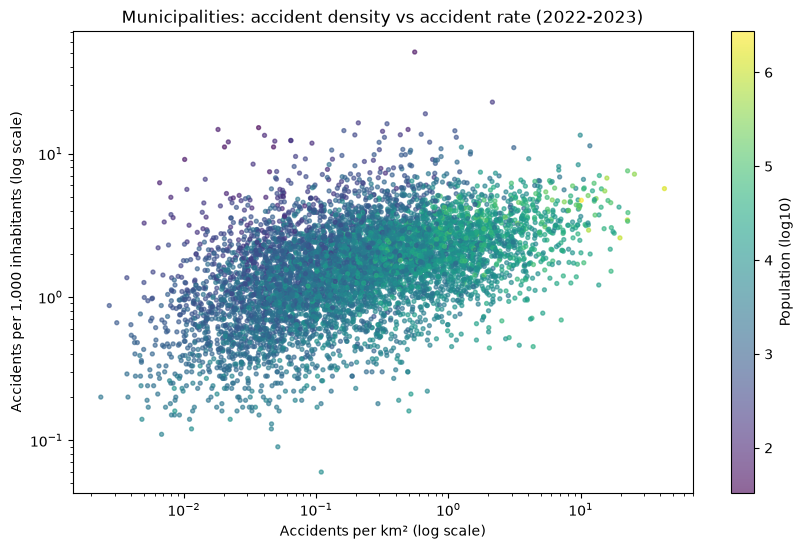

In [29]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = df_municipalities[df_municipalities["accidents"] > 0]

fig, ax = plt.subplots(figsize=(10, 6))
points = ax.scatter(plot_data["accidents_per_km2"], plot_data["accidents_per_1000_inh"],
                    c=np.log10(plot_data["POP_RES"]), cmap="viridis", s=8, alpha=0.6)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Accidents per km² (log scale)")
ax.set_ylabel("Accidents per 1,000 inhabitants (log scale)")
ax.set_title("Municipalities: accident density vs accident rate (2022-2023)")
fig.colorbar(points, label="Population (log10)")
plt.show()

The graph it's in log-log scale, beacuse the distributions are highly skewed.

The log-log scale allows us to visualize the data more clearly.

The municipalities with darker colors have lower population, while the municipalities with lighter colors have higher population.

In [30]:
df_municipalities = df_municipalities.merge(
    candidates[["REF_AREA", "score"]], on="REF_AREA", how="left"
)
df_municipalities["above_threshold"] = df_municipalities["score"].notna()
df_municipalities.to_csv("../data/processed/municipalities_indicators.csv", index=False)